# Exploration du dataset Chest X-Ray Pneumonia

Ce notebook décrit les données avant tout prétraitement. Il ne modifie aucun fichier et n'entraîne aucun modèle.

Les questions auxquelles il répond :
1. Combien d'images contient chaque dossier (train, val, test) et chaque classe ?
2. Les images ont-elles des tailles et des formats homogènes ?
3. Y a-t-il des fichiers corrompus ?
4. Les radiographies se ressemblent-elles, et les classes diffèrent-elles par des caractéristiques visibles qui ne sont pas liées à la maladie ?

In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(racine))

from src.config import DATA_DIR, CLASS_NAMES

SPLITS = ["train", "val", "test"]
EXTENSIONS = {".jpeg", ".jpg", ".png"}

print("Racine du projet :", racine)
print("Dossier du dataset :", DATA_DIR)
print("Classes :", CLASS_NAMES)

Racine du projet : C:\Users\Administrator\Documents\projets_machine_learning\chest-xray-pneumonia
Dossier du dataset : C:\Users\Administrator\Documents\projets_machine_learning\chest-xray-pneumonia\data\chest_xray
Classes : ('NORMAL', 'PNEUMONIA')


## 2. Nombre d'images par dossier et par classe

On construit un tableau qui liste chaque image avec son dossier, sa classe et son chemin. Cela permet de faire ensuite tous les comptages avec pandas.

In [8]:
records = []
for split in SPLITS:
    for cls in CLASS_NAMES:
        folder = DATA_DIR / split / cls
        for path in folder.iterdir():
            if path.suffix.lower() in EXTENSIONS:
                records.append({"split": split, "classe": cls, "chemin": path})

df = pd.DataFrame(records)
print("Nombre total d'images :", len(df))
df.groupby(["split", "classe"]).size().unstack()

Nombre total d'images : 5856


classe,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


## 3. Répartition des classes

Le tableau précédent montre le déséquilibre. Le graphique le rend plus visible, et permet de comparer la part de pneumonies dans chaque dossier.

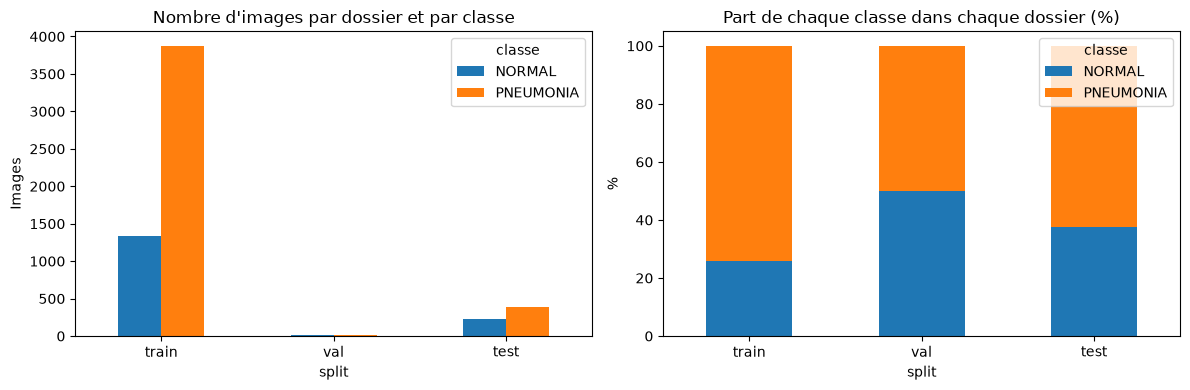

classe  NORMAL  PNEUMONIA
split                    
train     25.7       74.3
val       50.0       50.0
test      37.5       62.5


In [9]:
counts = df.groupby(["split", "classe"]).size().unstack().loc[SPLITS]
shares = counts.div(counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Nombre d'images par dossier et par classe")
axes[0].set_ylabel("Images")

shares.plot(kind="bar", stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Part de chaque classe dans chaque dossier (%)")
axes[1].set_ylabel("%")
plt.tight_layout()
plt.show()

print(shares.round(1))

## 4. Vérification de l'intégrité des fichiers

Un fichier corrompu fait planter l'entraînement au milieu d'une epoch. On tente d'ouvrir chaque image avec PIL, et on signale celles qui échouent. On enregistre aussi la taille et le mode couleur de chaque image, car ils peuvent varier d'une source à l'autre.

In [10]:
infos = []
errors = []
for row in df.itertuples():
    try:
        with Image.open(row.chemin) as img:
            infos.append({
                "split": row.split,
                "classe": row.classe,
                "largeur": img.width,
                "hauteur": img.height,
                "mode": img.mode,
            })
    except Exception as exc:
        errors.append((str(row.chemin), str(exc)))

info_df = pd.DataFrame(infos)
print("Images lisibles :", len(info_df))
print("Images corrompues :", len(errors))
for chemin, message in errors[:10]:
    print(chemin, "->", message)

Images lisibles : 5856
Images corrompues : 0


## 5. Tailles et modes des images

Si toutes les images ont la même taille et le même mode, le redimensionnement sera simple. Sinon, il faut décider de la méthode de conversion.

In [11]:
print("Modes couleur :")
print(info_df["mode"].value_counts())

print("\nTailles les plus fréquentes :")
print(info_df.groupby(["largeur", "hauteur"]).size().sort_values(ascending=False).head(10))

print("\nStatistiques des dimensions :")
print(info_df[["largeur", "hauteur"]].describe().round(0))

Modes couleur :
mode
L      5573
RGB     283
Name: count, dtype: int64

Tailles les plus fréquentes :
largeur  hauteur
1072     648        7
1008     704        7
992      608        6
1216     872        6
992      592        6
1080     728        6
1192     760        5
1088     712        5
976      672        5
1000     704        5
dtype: int64

Statistiques des dimensions :
       largeur  hauteur
count   5856.0   5856.0
mean    1328.0    971.0
std      364.0    383.0
min      384.0    127.0
25%     1056.0    688.0
50%     1281.0    888.0
75%     1560.0   1187.0
max     2916.0   2713.0


### Conclusion sur les formats

Les images sont en niveaux de gris pour 95 % d'entre elles (5 573 images en mode L), et en RGB pour 5 % (283 images). Leurs dimensions varient fortement, de 384 à 2 916 pixels en largeur, sans taille dominante.

Le redimensionnement à 224 × 224 est donc nécessaire. Il déforme légèrement les proportions, mais il conserve l'ensemble des poumons, contrairement à un recadrage central. Toutes les images seront converties en niveaux de gris puis répliquées sur trois canaux, ce qui correspond au format attendu par ResNet.

Il faudra vérifier que les images RGB sont bien en gris sur leurs trois canaux, et que la taille des images ne diffère pas entre les classes, pour ne pas laisser au modèle un raccourci.

## 6. Exemples de radiographies

On affiche quelques images de chaque classe, pour voir à quoi ressemblent les données. Les images sont prises au hasard, avec une graine fixe pour que l'affichage soit reproductible.

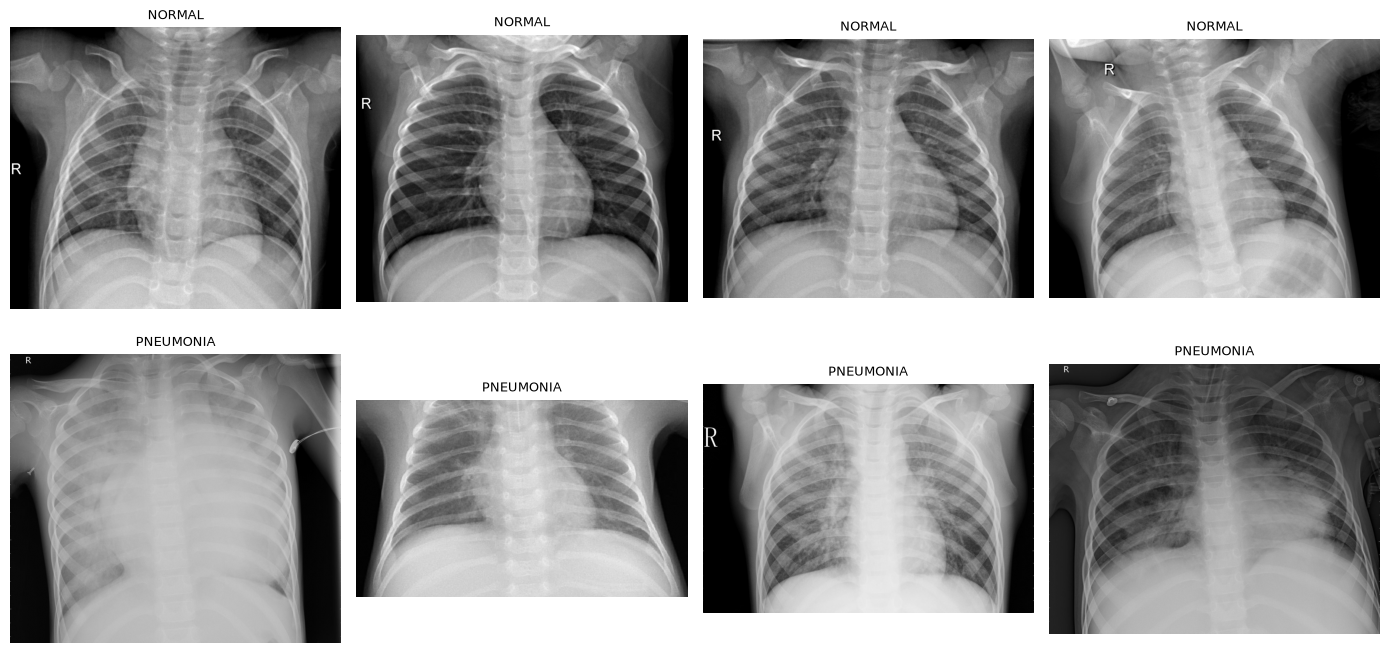

In [12]:
n_par_classe = 4

fig, axes = plt.subplots(len(CLASS_NAMES), n_par_classe, figsize=(14, 7))
for i, cls in enumerate(CLASS_NAMES):
    sous_ensemble = df[(df["split"] == "train") & (df["classe"] == cls)]
    choisis = sous_ensemble.sample(n=n_par_classe, random_state=42)
    for j, row in enumerate(choisis.itertuples()):
        axes[i, j].imshow(Image.open(row.chemin).convert("L"), cmap="gray")
        axes[i, j].set_title(cls, fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

### Conclusion visuelle

Les radiographies normales montrent des champs pulmonaires sombres et dégagés, avec des contours nets des côtes et du diaphragme. Les radiographies pneumoniques présentent des zones opaques ou blanchâtres, surtout dans les bases et les champs moyens, qui estompent ces contours. La différence visuelle est donc réelle et liée à la pathologie.

Plusieurs éléments parasites apparaissent : un tube médical sur une radiographie pneumonique, des cadrages et des bordures très variables, et des marqueurs d'orientation (« R ») dans les deux classes. Ces éléments peuvent servir de raccourcis au modèle. Pour limiter ce risque, l'entraînement utilisera une augmentation qui varie le cadrage, et l'analyse des erreurs vérifiera à l'aide de Grad-CAM que le modèle regarde les poumons.

## 7. Luminosité moyenne par classe

Un modèle peut apprendre des raccourcis : si les images de pneumonie sont plus claires à cause de l'appareil utilisé, il reconnaîtra la luminosité au lieu de la maladie. On compare donc la luminosité moyenne entre les deux classes, sur le train.

             mean    std  count
classe                         
NORMAL     122.38  12.96   1341
PNEUMONIA  123.20  20.11   3875


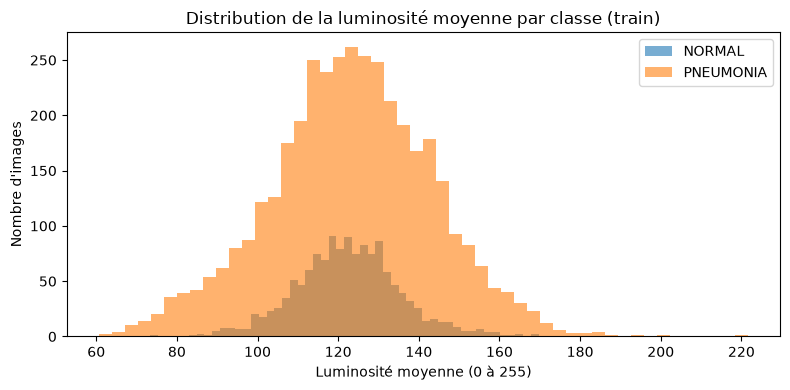

In [13]:
def luminosite_moyenne(path):
    with Image.open(path) as img:
        return float(np.asarray(img.convert("L").resize((224, 224)), dtype=np.float32).mean())

train_df = df[df["split"] == "train"].copy()
train_df["luminosite"] = [luminosite_moyenne(p) for p in train_df["chemin"]]

stats = train_df.groupby("classe")["luminosite"].agg(["mean", "std", "count"]).round(2)
print(stats)

fig, ax = plt.subplots(figsize=(8, 4))
for cls in CLASS_NAMES:
    ax.hist(train_df.loc[train_df["classe"] == cls, "luminosite"], bins=50, alpha=0.6, label=cls)
ax.set_title("Distribution de la luminosité moyenne par classe (train)")
ax.set_xlabel("Luminosité moyenne (0 à 255)")
ax.set_ylabel("Nombre d'images")
ax.legend()
plt.tight_layout()
plt.show()

### Conclusion sur la luminosité

La luminosité moyenne est pratiquement identique entre les deux classes : 122,4 pour les radiographies normales et 123,2 pour les pneumoniques. Les distributions se recouvrent largement. Le modèle ne peut donc pas s'appuyer sur la luminosité globale pour distinguer les classes.

En revanche, l'écart-type est plus élevé pour les pneumonies (20,1 contre 13,0). Cette dispersion reflète le contraste des opacités pulmonaires : c'est un signal lié à la maladie, et le modèle a le droit de l'utiliser.

Aucune normalisation spécifique par luminosité n'est donc nécessaire. La normalisation standard d'ImageNet suffit, à condition d'être appliquée de la même façon au train, à la validation et au test.

In [8]:
import sys
from pathlib import Path

racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
for nom in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[nom]
sys.path.insert(0, str(racine))

from src.config import DataConfig
from src.data import build_dataloaders

b = build_dataloaders(DataConfig())
x, y = next(iter(b.train))
print(x.shape, b.class_weights)

2026-10-10 19:51:34,349 | INFO     | src.data | Entraînement : 4433 images
2026-10-10 19:51:34,350 | INFO     | src.data | Validation   : 783 images
2026-10-10 19:51:34,351 | INFO     | src.data | Test         : 624 images
2026-10-10 19:51:34,351 | INFO     | src.data | Classe NORMAL     : train 1140, validation 201
2026-10-10 19:51:34,351 | INFO     | src.data | Classe PNEUMONIA  : train 3293, validation 582
2026-10-10 19:51:34,353 | INFO     | src.data | Poids de classe : [1.944, 0.673]


torch.Size([32, 3, 224, 224]) tensor([1.9443, 0.6731])


In [11]:
import sys
from pathlib import Path

racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
for nom in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[nom]
sys.path.insert(0, str(racine))

import torch
import torch.nn as nn
from src.config import ModelConfig
from src.model import build_model, set_train_mode, count_parameters
from src.utils import get_device

device = get_device()
modele = build_model(ModelConfig(freeze_backbone=False), unfreeze_last_block=False).to(device)
set_train_mode(modele)
print("paramètres (entraînables, total) :", count_parameters(modele))

optimiseur = torch.optim.AdamW(modele.parameters(), lr=1e-5)
scaler = torch.amp.GradScaler("cuda")
critere = nn.CrossEntropyLoss()

for taille in [16, 32]:
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    x = torch.randn(taille, 3, 224, 224, device=device)
    y = torch.randint(0, 2, (taille,), device=device)
    optimiseur.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=torch.float16):
        perte = critere(modele(x), y)
    scaler.scale(perte).backward()
    scaler.step(optimiseur)
    scaler.update()
    print(f"batch {taille} : mémoire pic {torch.cuda.max_memory_allocated() / 1e9:.2f} Go")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Administrator/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth
100.0%
2026-10-10 19:56:13,937 | INFO     | src.model | Modèle resnet50 : 23,512,130 paramètres entraînables sur 23,512,130 (dernier bloc dégelé : False)


paramètres (entraînables, total) : (23512130, 23512130)
batch 16 : mémoire pic 0.90 Go
batch 32 : mémoire pic 1.81 Go
